In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
#Step 1: Load and inspect

df = pd.read_csv("health_dataset.csv")
print("Dataset shape:", df.shape)

Dataset shape: (2500, 13)


In [ ]:
df.head(10)
df.tail()

,Patient_ID,Age,Gender,Smoking_Status,Years_of_Smoking,Cigarettes_Per_Day,Organ,Organ_Condition,BMI,BP_Risk,Cholesterol_Level,Family_History_Risk,Alcohol_Consumption
2495,2496,59,Male,Never,0,0,Human Body,Damaged,31.0,Normal,193.8,No,Low
2496,2497,69,Female,Never,0,0,Kidney,Healthy,24.2,Normal,210.4,No,Moderate
2497,2498,43,Male,Current,13,16,Heart,Healthy,39.9,Low,128.7,No,Moderate
2498,2499,43,Female,Current,15,6,Human Body,Healthy,41.2,Normal,129.3,Yes,Low
2499,2500,49,Male,Never,0,0,Lungs,Healthy,33.8,Low,129.7,No,High


In [ ]:
print("Dataset shape:", df.shape)
df.info()
df.describe()

Dataset shape: (2500, 13)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Patient_ID           2500 non-null   int64  
 1   Age                  2500 non-null   int64  
 2   Gender               2500 non-null   object 
 3   Smoking_Status       2500 non-null   object 
 4   Years_of_Smoking     2500 non-null   int64  
 5   Cigarettes_Per_Day   2500 non-null   int64  
 6   Organ                2500 non-null   object 
 7   Organ_Condition      2500 non-null   object 
 8   BMI                  2500 non-null   float64
 9   BP_Risk              2500 non-null   object 
 10  Cholesterol_Level    2500 non-null   float64
 11  Family_History_Risk  2500 non-null   object 
 12  Alcohol_Consumption  2500 non-null   object 
dtypes: float64(2), int64(4), object(7)
memory usage: 254.0+ KB


,Patient_ID,Age,Years_of_Smoking,Cigarettes_Per_Day,BMI,Cholesterol_Level
count,2500.00000,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000
mean,1250.50000,54.031600,8.976800,6.833200,29.620680,207.785600
std,721.83216,20.793738,11.155144,8.341583,7.239672,52.852446
min,1.00000,18.000000,0.000000,0.000000,17.000000,120.000000
25%,625.75000,36.000000,0.000000,0.000000,23.600000,161.700000
50%,1250.50000,54.000000,4.000000,3.000000,29.400000,206.650000
75%,1875.25000,72.000000,16.000000,12.000000,35.900000,253.625000
max,2500.00000,89.000000,39.000000,29.000000,42.000000,300.000000


In [ ]:
# Step 2: Check missing values and duplicates

print("Missing values:")
print(df.isnull().sum())

df.duplicated().sum()

Missing values:
Patient_ID             0
Age                    0
Gender                 0
Smoking_Status         0
Years_of_Smoking       0
Cigarettes_Per_Day     0
Organ                  0
Organ_Condition        0
BMI                    0
BP_Risk                0
Cholesterol_Level      0
Family_History_Risk    0
Alcohol_Consumption    0
dtype: int64


np.int64(0)

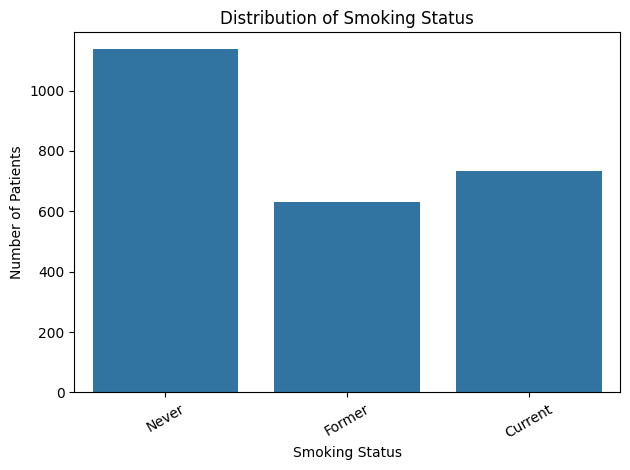

In [ ]:
#Step 3: Create graphs

# Graph 1: Smoking status
sns.countplot(data=df, x="Smoking_Status")
plt.title("Distribution of Smoking Status")
plt.xlabel("Smoking Status")
plt.ylabel("Number of Patients")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

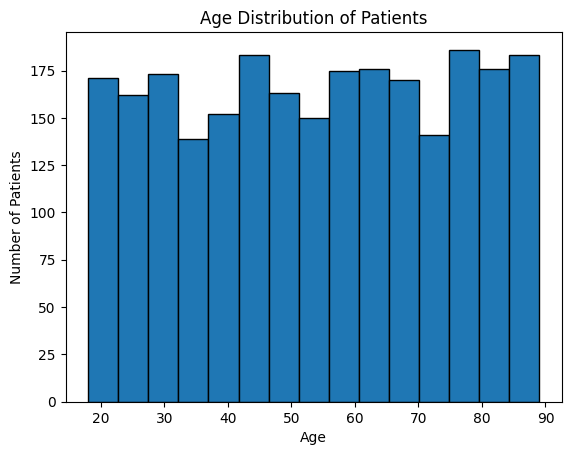

In [ ]:

# Graph 2: Age distribution
plt.hist(df["Age"], bins=15, edgecolor="black")
plt.title("Age Distribution of Patients")
plt.xlabel("Age")
plt.ylabel("Number of Patients")
plt.show()

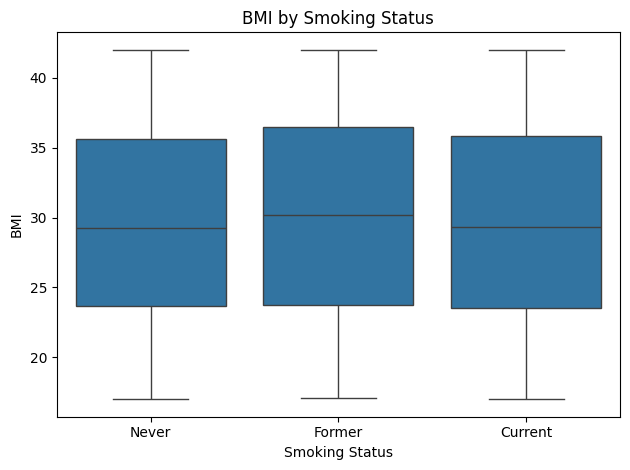

In [ ]:
# Graph 3: BMI by smoking status
sns.boxplot(data=df, x="Smoking_Status", y="BMI")
plt.title("BMI by Smoking Status")
plt.xlabel("Smoking Status")
plt.ylabel("BMI")
plt.tight_layout()
plt.show()

In [ ]:
# Step 4: Clean, Encode and Scale

# Make a copy of the dataset
clean_df = df.copy()

# Remove duplicate rows
clean_df = clean_df.drop_duplicates()

# Remove Patient_ID column
clean_df = clean_df.drop(columns=["Patient_ID"])

# Encode categorical columns
clean_df = pd.get_dummies(clean_df, dtype=int)


columns = [
    "Age",
    "Years_of_Smoking",
    "Cigarettes_Per_Day",
    "BMI",
    "Cholesterol_Level"
]



# Display prepared dataset
display(clean_df.head())

print("Final dataset shape:", clean_df.shape)

,Age,Years_of_Smoking,Cigarettes_Per_Day,BMI,Cholesterol_Level,Gender_Female,Gender_Male,Smoking_Status_Current,Smoking_Status_Former,Smoking_Status_Never,...,Organ_Condition_Damaged,Organ_Condition_Healthy,BP_Risk_High,BP_Risk_Low,BP_Risk_Normal,Family_History_Risk_No,Family_History_Risk_Yes,Alcohol_Consumption_High,Alcohol_Consumption_Low,Alcohol_Consumption_Moderate
0,32,0,0,28.1,202.7,0,1,0,0,1,...,0,1,0,1,0,1,0,0,1,0
1,47,2,8,21.6,214.5,1,0,0,1,0,...,0,1,0,0,1,1,0,0,1,0
2,77,10,12,41.6,274.8,1,0,0,1,0,...,0,1,0,0,1,1,0,0,1,0
3,77,0,0,17.4,163.4,1,0,0,0,1,...,0,1,0,0,1,1,0,0,0,1
4,53,39,18,30.0,153.3,1,0,1,0,0,...,0,1,0,0,1,1,0,0,0,1


Final dataset shape: (2500, 25)


In [ ]:
#Step 5: Save the prepared dataset

# Save the prepared dataset
clean_df.to_csv("smoking_health_prepared.csv", index=False)

# Check final dataset
print("Final shape:", clean_df.shape)
print("Missing values:", clean_df.isnull().sum().sum())
print("Duplicate rows:", clean_df.duplicated().sum())

# Display first five rows
display(clean_df.head())

Final shape: (2500, 25)
Missing values: 0
Duplicate rows: 0


,Age,Years_of_Smoking,Cigarettes_Per_Day,BMI,Cholesterol_Level,Gender_Female,Gender_Male,Smoking_Status_Current,Smoking_Status_Former,Smoking_Status_Never,...,Organ_Condition_Damaged,Organ_Condition_Healthy,BP_Risk_High,BP_Risk_Low,BP_Risk_Normal,Family_History_Risk_No,Family_History_Risk_Yes,Alcohol_Consumption_High,Alcohol_Consumption_Low,Alcohol_Consumption_Moderate
0,32,0,0,28.1,202.7,0,1,0,0,1,...,0,1,0,1,0,1,0,0,1,0
1,47,2,8,21.6,214.5,1,0,0,1,0,...,0,1,0,0,1,1,0,0,1,0
2,77,10,12,41.6,274.8,1,0,0,1,0,...,0,1,0,0,1,1,0,0,1,0
3,77,0,0,17.4,163.4,1,0,0,0,1,...,0,1,0,0,1,1,0,0,0,1
4,53,39,18,30.0,153.3,1,0,1,0,0,...,0,1,0,0,1,1,0,0,0,1
